# Preparação e transformação de dados — Valorant universitário

Adaptação do notebook de aula *Preparação e transformação de dados* (Francisco A. Rodrigues, ICMC-USP) para os dados do hackathon: **336 partidas** de Valorant de campeonatos universitários brasileiros (Rush Series Esquenta, Rush Series Esquenta 2, Rush Series Inclusivo e Univavá).

<hr>

Em Ciência de Dados, a qualidade do modelo depende diretamente da qualidade dos dados. No notebook original os problemas eram artificiais (uma Iris com `?` e linhas repetidas). Aqui eles são **reais**: vêm do formato da API de partidas da Riot e da forma como os arquivos foram organizados.

Seguiremos as mesmas etapas:
1. identificar problemas comuns em bases de dados, como valores ausentes, duplicatas e registros inconsistentes;
2. aplicar procedimentos básicos de limpeza usando `pandas` e `numpy`;
3. substituir valores ausentes por medidas como média e mediana (e discutir quando **não** fazer isso);
4. normalizar e padronizar atributos numéricos;
5. converter variáveis categóricas em variáveis numéricas;
6. identificar variáveis altamente correlacionadas;
7. avaliar desbalanceamento de classes.

Ao final, as bases tratadas são salvas em `outputs/processed/` e usadas pelo notebook `valorant-exploratory-data-analysis.ipynb`.

### 0. Contexto: de onde vêm os dados

Cada arquivo `data/<torneio ou fase>/<PREFIXO>_<NÚMERO>_<dd-mm-aa>_<time_a>_<placar_a>_x_<placar_b>_<time_b>_<mapa>.json` (o torneio vem do prefixo — `RUSHE`, `RUSH2`, `RUSH_INCLUSIVO`, `UNIVAVA_*` — e a fase da Univavá, da pasta) é uma partida no formato *match-v1* da Riot, com quatro blocos:

| bloco | conteúdo |
|---|---|
| `matchInfo` | id, mapa (nome interno, ex.: `Triad` = Haven), versão do jogo, duração, início |
| `players` | 10 jogadores (às vezes + observador): agente (UUID), time `Red`/`Blue`, kills, deaths, assists, score, uso de habilidades |
| `teams` | rounds ganhos e vencedor por lado `Red`/`Blue` |
| `roundResults` | para cada round: vencedor, lado vencedor (ataque/defesa), tipo de vitória, plant/defuse, e por jogador a economia, o dano causado e cada abate |

Duas adequações foram necessárias para tornar a análise possível:

1. **Nomes dos times não estão no JSON** — só `Red`/`Blue`. Eles são recuperados do nome do arquivo, associando o placar do arquivo aos `roundsWon` de cada lado (o placar bate em 100% dos arquivos).
2. **Agentes, armas, armaduras e mapas são UUIDs/nomes internos.** O arquivo `reference/valorant_reference.json` traz a tradução, baixada do [valorant-api.com](https://valorant-api.com) (pt-BR). Três UUIDs de "armas" que não existem no catálogo (armas de habilidade de Chamber e Neon) foram identificados pelo agente de quem fez o abate.

O módulo `src/valorant_data.py` faz apenas o **achatamento** dos JSONs em quatro tabelas, **sem limpar nada** — a limpeza é o assunto deste notebook:

- `jogadores`: uma linha por jogador por partida, com métricas agregadas dos rounds (dano, headshots, first kills, KAST, plants…);
- `rounds`: uma linha por round, com economia de atacantes e defensores;
- `economia`: uma linha por jogador por round (arma e armadura compradas);
- `abates`: uma linha por abate.

### 1. Bibliotecas utilizadas

Usaremos `pandas`, `numpy`, `matplotlib`, `seaborn` e `scikit-learn`, além do módulo local `valorant_data`. Também definimos uma semente aleatória para garantir a reprodutibilidade.

In [1]:
import random # fixar semente, garante reprodutibilidade
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Torna o módulo src/valorant_data.py importável, de onde quer que o notebook seja aberto.
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "valorant_data.py").exists())
sys.path.insert(0, str(RAIZ / "src"))

from valorant_data import (PASTA_PROCESSADOS, carregar_tabelas, carregar_referencia, nomear_itens,
                           aplicar_estilo, CORES, CORES_FUNCAO, ORDEM_FUNCAO)

# Define sementes aleatórias para reprodutibilidade.
random.seed(1)
np.random.seed(1)

# Configuração simples para melhorar a visualização das tabelas.
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

CMAP_SEQ, CMAP_DIV = aplicar_estilo()

### 2. Leitura de uma base com problemas

Lemos todos os 336 JSONs e começamos pela tabela `jogadores`.

In [2]:
tabelas = carregar_tabelas()
ref = carregar_referencia()

for nome, tabela in tabelas.items():
    print(f"{nome:10s}: {tabela.shape[0]:>6} linhas x {tabela.shape[1]} colunas")

data = tabelas["jogadores"].copy()
print("\nNúmero de linhas e colunas:", data.shape)
data.head(10)

jogadores :   3382 linhas x 54 colunas
rounds    :   6618 linhas x 28 colunas
economia  :  66180 linhas x 12 colunas
abates    :  46753 linhas x 13 colunas

Número de linhas e colunas: (3382, 54)


,arquivo,torneio,fase,codigo,data,match_id,mapa,versao_jogo,duracao_min,inicio,regiao,modo,is_ranked,provisioning_flow,custom_game_name,...,rounds_ganhos_adversario,venceu,dano,dano_recebido,headshots,bodyshots,legshots,first_kills,first_deaths,plants,defuses,kast_rounds,multikills,loadout_total,gasto_total
0,UNIVAVA_C1_002_27-06-26_poli_plague_10_x_13_un...,Univavá,Classificatória 1,002,2026-06-27,fc187928-9b72-42b3-aaaf-8ca6689a3937,Haven,release-13.00-shipping-32-4990475,45.032433,2026-06-27 17:26:22.281,br,BombGameMode,False,CustomGame,,...,10.0,True,2955.0,3032.0,7.0,44.0,3.0,2.0,0.0,7.0,2.0,17.0,0.0,85950.0,58150.0
1,UNIVAVA_C1_002_27-06-26_poli_plague_10_x_13_un...,Univavá,Classificatória 1,002,2026-06-27,fc187928-9b72-42b3-aaaf-8ca6689a3937,Haven,release-13.00-shipping-32-4990475,45.032433,2026-06-27 17:26:22.281,br,BombGameMode,False,CustomGame,,...,10.0,True,4047.0,3062.0,19.0,33.0,1.0,3.0,2.0,0.0,0.0,14.0,1.0,82650.0,53950.0
2,UNIVAVA_C1_002_27-06-26_poli_plague_10_x_13_un...,Univavá,Classificatória 1,002,2026-06-27,fc187928-9b72-42b3-aaaf-8ca6689a3937,Haven,release-13.00-shipping-32-4990475,45.032433,2026-06-27 17:26:22.281,br,BombGameMode,False,CustomGame,,...,10.0,True,2656.0,2835.0,7.0,39.0,5.0,3.0,2.0,2.0,0.0,15.0,0.0,89450.0,51750.0
3,UNIVAVA_C1_002_27-06-26_poli_plague_10_x_13_un...,Univavá,Classificatória 1,002,2026-06-27,fc187928-9b72-42b3-aaaf-8ca6689a3937,Haven,release-13.00-shipping-32-4990475,45.032433,2026-06-27 17:26:22.281,br,BombGameMode,False,CustomGame,,...,10.0,True,2876.0,3300.0,9.0,30.0,6.0,2.0,4.0,0.0,0.0,14.0,1.0,85400.0,64000.0
4,UNIVAVA_C1_002_27-06-26_poli_plague_10_x_13_un...,Univavá,Classificatória 1,002,2026-06-27,fc187928-9b72-42b3-aaaf-8ca6689a3937,Haven,release-13.00-shipping-32-4990475,45.032433,2026-06-27 17:26:22.281,br,BombGameMode,False,CustomGame,,...,13.0,False,5498.0,3069.0,8.0,43.0,1.0,8.0,4.0,0.0,0.0,17.0,4.0,95650.0,58050.0
5,UNIVAVA_C1_002_27-06-26_poli_plague_10_x_13_un...,Univavá,Classificatória 1,002,2026-06-27,fc187928-9b72-42b3-aaaf-8ca6689a3937,Haven,release-13.00-shipping-32-4990475,45.032433,2026-06-27 17:26:22.281,br,BombGameMode,False,CustomGame,,...,10.0,True,3931.0,2895.0,13.0,50.0,2.0,3.0,2.0,0.0,1.0,17.0,5.0,93400.0,47400.0
6,UNIVAVA_C1_002_27-06-26_poli_plague_10_x_13_un...,Univavá,Classificatória 1,002,2026-06-27,fc187928-9b72-42b3-aaaf-8ca6689a3937,Haven,release-13.00-shipping-32-4990475,45.032433,2026-06-27 17:26:22.281,br,BombGameMode,False,CustomGame,,...,13.0,False,1944.0,3252.0,6.0,49.0,2.0,0.0,3.0,1.0,0.0,19.0,0.0,77150.0,57300.0
7,UNIVAVA_C1_002_27-06-26_poli_plague_10_x_13_un...,Univavá,Classificatória 1,002,2026-06-27,fc187928-9b72-42b3-aaaf-8ca6689a3937,Haven,release-13.00-shipping-32-4990475,45.032433,2026-06-27 17:26:22.281,br,BombGameMode,False,CustomGame,,...,13.0,False,1929.0,3197.0,9.0,33.0,0.0,0.0,2.0,1.0,1.0,17.0,0.0,88300.0,59450.0
8,UNIVAVA_C1_002_27-06-26_poli_plague_10_x_13_un...,Univavá,Classificatória 1,002,2026-06-27,fc187928-9b72-42b3-aaaf-8ca6689a3937,Haven,release-13.00-shipping-32-4990475,45.032433,2026-06-27 17:26:22.281,br,BombGameMode,False,CustomGame,,...,13.0,False,3013.0,3440.0,12.0,17.0,0.0,1.0,2.0,7.0,0.0,15.0,0.0,77450.0,61500.0
9,UNIVAVA_C1_002_27-06-26_poli_plague_10_x_13_un...,Univavá,Classificatória 1,002,2026-06-27,fc187928-9b72-42b3-aaaf-8ca6689a3937,Haven,release-13.00-shipping-32-4990475,45.032433,2026-06-27 17:26:22.281,br,BombGameMode,False,CustomGame,,...,13.0,False,2740.0,3507.0,12.0,34.0,2.0,1.0,2.0,1.0,0.0,17.0,1.0,84250.0,62200.0


Antes de aplicar qualquer técnica estatística, é importante **inspecionar os dados**:

- Quantas linhas e colunas existem?
- Quais colunas são numéricas e quais são categóricas?
- Há valores ausentes?
- Há registros duplicados?

In [3]:
print("Colunas da base:")
print(list(data.columns))

print("\nTipos de dados:")
print(data.dtypes.value_counts())

ausentes = data.isna().sum()
print("\nQuantidade de valores ausentes por coluna (apenas colunas com ausentes):")
print(ausentes[ausentes > 0])

print("\nNúmero de linhas duplicadas:", data.duplicated().sum())

Colunas da base:
['arquivo', 'torneio', 'fase', 'codigo', 'data', 'match_id', 'mapa', 'versao_jogo', 'duracao_min', 'inicio', 'regiao', 'modo', 'is_ranked', 'provisioning_flow', 'custom_game_name', 'queue_id', 'n_rounds', 'puuid', 'nick', 'party_id', 'team_id', 'time', 'adversario', 'is_observer', 'agente', 'funcao', 'competitive_tier', 'account_level', 'score', 'rounds_jogados', 'kills', 'deaths', 'assists', 'playtime_min', 'grenade_casts', 'ability1_casts', 'ability2_casts', 'ultimate_casts', 'rounds_ganhos_time', 'rounds_ganhos_adversario', 'venceu', 'dano', 'dano_recebido', 'headshots', 'bodyshots', 'legshots', 'first_kills', 'first_deaths', 'plants', 'defuses', 'kast_rounds', 'multikills', 'loadout_total', 'gasto_total']

Tipos de dados:
float64           26
str               20
int64              3
bool               2
datetime64[us]     1
datetime64[ms]     1
object             1
Name: count, dtype: int64

Quantidade de valores ausentes por coluna (apenas colunas com ausentes):


Exatamente **22 linhas** têm valores ausentes em praticamente todas as colunas de desempenho. Vamos ver quem são.

In [4]:
linhas_com_nan = data[data.isna().any(axis=1)]
print("Linhas com algum NaN:", len(linhas_com_nan))
print("\nValores de team_id e is_observer nessas linhas:")
print(linhas_com_nan[["team_id", "is_observer"]].value_counts())

linhas_com_nan[["arquivo", "nick", "team_id", "is_observer", "agente", "kills", "deaths"]].head()

Linhas com algum NaN: 22

Valores de team_id e is_observer nessas linhas:
team_id  is_observer
Neutral  True           22
Name: count, dtype: int64


,arquivo,nick,team_id,is_observer,agente,kills,deaths
84,UNIVAVA_C1_039_27-06-26_ceub_octopus_vulgaris_...,JotaVe#2511,Neutral,True,NaN,NaN,NaN
622,UNIVAVA_C2_014_25-07-26_rahnag_3_x_13_ufu_sain...,Luleka#6977,Neutral,True,NaN,NaN,NaN
992,UNIVAVA_C3_010_15-08-26_azure_bears_silver_11_...,Manuzinha LEI#TFx,Neutral,True,NaN,NaN,NaN
1103,UNIVAVA_C3_023_15-08-26_azure_bears_black_6_x_...,Manuzinha LEI#TFx,Neutral,True,NaN,NaN,NaN
1139,UNIVAVA_C3_027_15-08-26_caap_malditos_13_x_11_...,Manuzinha LEI#TFx,Neutral,True,NaN,NaN,NaN


São os **observadores** das partidas transmitidas: entram na lista `players` do JSON, mas pertencem ao time `Neutral`, não têm agente nem estatísticas. Não são jogadores — devem sair da base.

### 3. Remoção de valores ausentes

Aqui `dropna()` é a escolha correta: os NaN não são "dados perdidos" de um jogador real, e sim registros que não pertencem à população estudada.

In [5]:
data_sem_nan = data.dropna()

print("Dimensão original:", data.shape)
print("Dimensão após remover NaN:", data_sem_nan.shape)
print("Ainda há observadores?", data_sem_nan["is_observer"].any())

# Cada partida deve ter exatamente 5 jogadores por time.
print("\nJogadores por (partida, time):")
print(data_sem_nan.groupby(["match_id", "team_id"]).size().value_counts())

Dimensão original: (3382, 54)
Dimensão após remover NaN: (3360, 54)
Ainda há observadores? False

Jogadores por (partida, time):
5    672
Name: count, dtype: int64


Após a remoção, todas as 336 partidas ficam com exatamente 5 jogadores em cada um dos 2 times — 3360 linhas.

### 4. Identificação e remoção de linhas duplicadas

A função `duplicated()` indica quais linhas já apareceram anteriormente na tabela. Além de linhas idênticas, verificamos a **chave** da tabela: um jogador (`puuid`) não pode aparecer duas vezes na mesma partida (`match_id`).

In [6]:
linhas_duplicadas = data_sem_nan.duplicated()
print("Linhas completamente duplicadas:", linhas_duplicadas.sum())
print("Pares (match_id, puuid) duplicados:", data_sem_nan.duplicated(subset=["match_id", "puuid"]).sum())
print("Partidas distintas:", data_sem_nan["match_id"].nunique(), "| arquivos:", data_sem_nan["arquivo"].nunique())

Linhas completamente duplicadas: 0
Pares (match_id, puuid) duplicados: 0
Partidas distintas: 336 | arquivos: 336


Não há duplicatas exatas. Mas existem **duplicatas aparentes**: partidas com o mesmo confronto, mapa e placar. Elas são duplicatas legítimas ou erro de registro?

In [7]:
partidas = data_sem_nan.drop_duplicates(["match_id", "time"])
chave_confronto = ["time", "adversario", "mapa", "rounds_ganhos_time", "rounds_ganhos_adversario"]

suspeitas = partidas[partidas.duplicated(subset=chave_confronto, keep=False)]
suspeitas = suspeitas[suspeitas["venceu"]]  # uma linha por partida (o vencedor)
suspeitas[["arquivo", "match_id", "inicio", "duracao_min"] + chave_confronto].sort_values("time")

,arquivo,match_id,inicio,duracao_min,time,adversario,mapa,rounds_ganhos_time,rounds_ganhos_adversario
2824,RUSHE_015_06-06-26_azure_bears_golden_13_x_4_c...,fbcdac1d-69e7-4f93-962e-00fbba95dd99,2026-06-06 21:22:08.384,31.827317,Azure Bears Golden,Ceub Octopus Vulgaris,Ascent,13.0,4.0
2978,RUSHE_030b_07-06-26_azure_bears_golden_13_x_4_...,58fa1746-5856-4549-bb99-525afa81ce0b,2026-06-07 22:11:58.638,35.768850,Azure Bears Golden,Ceub Octopus Vulgaris,Ascent,13.0,4.0


As partidas suspeitas têm `match_id`, horário de início e duração diferentes: são **revanches reais** (por exemplo, Azure Bears Golden venceu Ceub Octopus Vulgaris por 13-4 em Ascent duas vezes no mesmo fim de semana — `RUSHE_015` e `RUSHE_030b`). Como o texto do notebook original alerta, *em alguns casos, duplicatas são legítimas* — essas devem ficar.

Para ilustrar o caso em que a duplicata **é** um erro, simulamos uma falha comum de integração: carregar a pasta de um torneio duas vezes.

In [8]:
integracao_errada = pd.concat([data_sem_nan, data_sem_nan[data_sem_nan["torneio"] == "Rush Series Inclusivo"]])
print("Dimensão com a pasta carregada duas vezes:", integracao_errada.shape)
print("Número de linhas duplicadas:", integracao_errada.duplicated().sum())

# Remove as linhas duplicadas.
data_limpa = integracao_errada.drop_duplicates()

print("Dimensão antes da remoção:", integracao_errada.shape)
print("Dimensão depois da remoção:", data_limpa.shape)

Dimensão com a pasta carregada duas vezes: (3490, 54)
Número de linhas duplicadas: 130
Dimensão antes da remoção: (3490, 54)
Dimensão depois da remoção: (3360, 54)


#### 4.1 Registros inconsistentes: o mesmo jogador com nicks diferentes

O `nick` (gameName#tagLine) pode ser trocado pelo jogador a qualquer momento; o identificador estável é o `puuid`. Agrupar por nick dividiria um mesmo jogador em vários.

In [9]:
nicks_por_jogador = data_limpa.groupby("puuid")["nick"].nunique()
print("Jogadores distintos (puuid):", data_limpa["puuid"].nunique())
print("Nicks distintos:", data_limpa["nick"].nunique())
print("\nQuantidade de nicks por jogador:")
print(nicks_por_jogador.value_counts().sort_index())

exemplo = nicks_por_jogador[nicks_por_jogador == nicks_por_jogador.max()].index[0]
data_limpa.loc[data_limpa["puuid"] == exemplo, ["data", "torneio", "nick", "time"]].sort_values("data")

Jogadores distintos (puuid): 411
Nicks distintos: 475

Quantidade de nicks por jogador:
nick
1    349
2     60
3      2
Name: count, dtype: int64


,data,torneio,nick,time
3101,2026-06-20,Rush Series Esquenta 2,237#fany,Totale Umc
3067,2026-06-20,Rush Series Esquenta 2,237#fany,Totale Umc
3016,2026-06-20,Rush Series Esquenta 2,237#fany,Totale Umc
3221,2026-06-21,Rush Series Esquenta 2,237#fany,Totale Umc
3106,2026-06-21,Rush Series Esquenta 2,237#fany,Totale Umc
148,2026-06-27,Univavá,237#fany,Totale Umc
225,2026-06-27,Univavá,237#fany,Totale Umc
280,2026-06-27,Univavá,237#fany,Totale Umc
478,2026-06-28,Univavá,237#fany,Totale Umc
1126,2026-08-15,Univavá,th ˆˆ#fany,Totale Umc


Padronizamos usando o nick **mais recente** de cada `puuid` na coluna `jogador`. O mesmo vale para times: alguns jogadores atuaram por mais de uma equipe, então o time é sempre lido da partida, nunca do jogador.

In [10]:
nick_atual = data_limpa.sort_values("inicio").groupby("puuid")["nick"].last()
data_limpa["jogador"] = data_limpa["puuid"].map(nick_atual)

print("Nicks distintos após padronização:", data_limpa["jogador"].nunique())
print("Jogadores que atuaram por mais de um time:", (data_limpa.groupby("puuid")["time"].nunique() > 1).sum())

Nicks distintos após padronização: 411
Jogadores que atuaram por mais de um time: 24


### 5. Tratamento de valores faltantes "escondidos"

Nem sempre valores faltantes aparecem como `NaN`. Na Iris eles eram `?`; nos JSONs da Riot são **strings vazias** `""` e, em campos numéricos, **zeros**. Vejamos a tabela `economia` (uma linha por jogador por round).

In [11]:
economia = tabelas["economia"].copy()

print("NaN por coluna:", economia.isna().sum().sum())
print("\nStrings vazias por coluna:")
vazias = (economia == "").sum()
print(vazias[vazias > 0])

NaN por coluna: 0

Strings vazias por coluna:


arma_uuid           16
armadura_uuid    10555
dtype: int64


O `isna()` diz que a base está completa, mas 10.555 registros não têm armadura e 16 não têm arma. Substituímos `""` por `np.nan`, a representação padrão de ausência no `pandas`, e traduzimos os UUIDs.

In [12]:
# Substitui a string vazia por NaN.
economia = economia.replace("", np.nan)

economia["arma"] = nomear_itens(economia["arma_uuid"], ref, "weapons")
economia["armadura"] = nomear_itens(economia["armadura_uuid"], ref, "gear")

print("Valores ausentes por coluna após substituir '':")
print(economia.isna().sum()[lambda s: s > 0])
economia[["round", "time", "lado", "loadout", "gasto", "banco", "arma", "armadura"]].head(10)

Valores ausentes por coluna após substituir '':


arma_uuid           16
armadura_uuid    10555
arma                16
armadura         10555
dtype: int64


,round,time,lado,loadout,gasto,banco,arma,armadura
0,1,Poli Plague,Attacker,600,800,0,Classic,NaN
1,1,Poli Plague,Attacker,1000,750,50,Ghost,NaN
2,1,Unicamp Tritons Red,Defender,800,800,0,Ghost,NaN
3,1,Poli Plague,Attacker,600,600,200,Classic,Armadura Leve
4,1,Unicamp Tritons Red,Defender,950,700,100,Ghost,NaN
5,1,Unicamp Tritons Red,Defender,600,800,0,Ghost,NaN
6,1,Poli Plague,Attacker,700,700,100,Classic,NaN
7,1,Unicamp Tritons Red,Defender,800,800,0,Ghost,NaN
8,1,Poli Plague,Attacker,900,750,50,Ghost,NaN
9,1,Unicamp Tritons Red,Defender,900,750,50,Ghost,NaN


Agora poderíamos usar `dropna()`. Mas **remover linhas é apenas uma das possibilidades** — antes, precisamos entender *por que* o valor falta.

In [13]:
sem_armadura = economia["armadura"].isna()
print(f"Registros sem armadura: {sem_armadura.sum()} ({sem_armadura.mean():.1%} da base)")

print("\nLoadout médio (valor do equipamento):")
print(economia.groupby(sem_armadura)["loadout"].mean().rename({False: "com armadura", True: "sem armadura"}).round(0))

primeiros_rounds = economia["round"].isin([1, 13])
print(f"\nFração sem armadura nos pistol rounds (rounds 1 e 13): {sem_armadura[primeiros_rounds].mean():.1%}")
print(f"Fração sem armadura nos demais rounds:               {sem_armadura[~primeiros_rounds].mean():.1%}")

Registros sem armadura: 10555 (15.9% da base)

Loadout médio (valor do equipamento):
armadura
com armadura    4042.0
sem armadura     791.0
Name: loadout, dtype: float64

Fração sem armadura nos pistol rounds (rounds 1 e 13): 78.8%
Fração sem armadura nos demais rounds:               8.8%


A ausência de armadura **não é aleatória**: concentra-se nos pistol rounds e nos rounds de economia (loadout baixo). Ela significa "o jogador não comprou armadura" — é informação, não falha de coleta. Um `dropna()` apagaria 16% da base e quase todos os rounds de eco, enviesando qualquer análise de economia.

Decisão:
- `armadura` ausente → categoria explícita **"Sem armadura"**;
- `arma` ausente (16 registros, 0,02%) → removidos, pois são raros e não há como recuperar a informação.

In [14]:
economia_limpa = (economia
                  .dropna(subset=["arma"])
                  .fillna({"armadura": "Sem armadura", "armadura_uuid": ""})
                  .drop_duplicates())

print("Dimensão original:", economia.shape)
print("Dimensão após limpeza:", economia_limpa.shape)
print(economia_limpa["armadura"].value_counts())

Dimensão original: (66180, 14)
Dimensão após limpeza: (66164, 14)
armadura
Armadura Pesada        40521
Armadura Leve          10796
Sem armadura           10545
Escudo Regenerativo     4302
Name: count, dtype: int64


O mesmo acontece na tabela `rounds`: quando não há plant, a API grava `plant_site = ""` e `plant_tempo_s = 0`. Um tempo de plant igual a zero é impossível (a spike leva segundos para ser plantada) — é um valor ausente disfarçado de número, e deixá-lo como 0 puxaria a média para baixo.

In [15]:
rounds = tabelas["rounds"].copy()

print("plant_site vazio:     ", (rounds["plant_site"] == "").sum())
print("plant_tempo_s == 0:   ", (rounds["plant_tempo_s"] == 0).sum())
print("defuse_tempo_s == 0:  ", (rounds["defuse_tempo_s"] == 0).sum())
print("\nMédia do tempo de plant com os zeros: ", round(rounds["plant_tempo_s"].mean(), 1), "s")

rounds = rounds.replace({"plant_site": {"": np.nan}})
rounds[["plant_tempo_s", "defuse_tempo_s"]] = rounds[["plant_tempo_s", "defuse_tempo_s"]].replace(0, np.nan)

print("Média do tempo de plant sem os zeros: ", round(rounds["plant_tempo_s"].mean(), 1), "s")
print("\nValores ausentes por coluna:")
print(rounds.isna().sum()[lambda s: s > 0])

plant_site vazio:      1965
plant_tempo_s == 0:    1965
defuse_tempo_s == 0:   5269

Média do tempo de plant com os zeros:  34.2 s
Média do tempo de plant sem os zeros:  48.7 s

Valores ausentes por coluna:
plant_site        1965
plant_tempo_s     1965
defuse_tempo_s    5269
dtype: int64


### 6. Remoção de linhas e colunas específicas

Usamos `drop()` com `axis=1` para colunas e `axis=0` para linhas.

Uma boa prática é remover **colunas constantes**: não carregam informação. Nos dados, todas as partidas são *custom games* na região `br`, no modo `Bomb`, sem ranqueamento, e o `competitive_tier` é sempre 0 (a API não expõe o elo em partidas personalizadas). Também removemos identificadores sem uso analítico (`party_id`).

In [16]:
constantes = [c for c in data_limpa.columns if data_limpa[c].nunique(dropna=False) == 1]
print("Colunas constantes:")
for c in constantes:
    print(f"  {c:20s} -> {data_limpa[c].iloc[0]!r}")

colunas_removidas = constantes + ["party_id"]
data_limpa = data_limpa.drop(columns=colunas_removidas)   # equivalente a drop(..., axis=1)
print("\nDimensão após remover colunas:", data_limpa.shape)

Colunas constantes:
  regiao               -> 'br'
  modo                 -> 'BombGameMode'
  is_ranked            -> np.False_
  provisioning_flow    -> 'CustomGame'
  custom_game_name     -> ''
  queue_id             -> ''
  is_observer          -> np.False_
  competitive_tier     -> np.int64(0)

Dimensão após remover colunas: (3360, 46)


Também podemos remover linhas específicas usando seus índices. Por exemplo, para uma análise por mapa, mapas com pouquíssimas partidas (Fracture e Pearl) geram estimativas instáveis. Removemos essas linhas apenas de uma cópia usada para comparações entre mapas.

In [17]:
print("Partidas por mapa:")
print(data_limpa.drop_duplicates("match_id")["mapa"].value_counts())

exemplo_drop_linhas = data_limpa.copy()
indices_removidos = exemplo_drop_linhas.index[exemplo_drop_linhas["mapa"].isin(["Fracture", "Pearl"])]
print("\nNúmero de linhas que serão removidas:", len(indices_removidos))

exemplo_drop_linhas = exemplo_drop_linhas.drop(indices_removidos, axis=0)
print("Dimensão após remover as linhas:", exemplo_drop_linhas.shape)

Partidas por mapa:


mapa
Ascent      86
Lotus       82
Haven       75
Split       36
Sunset      24
Abyss       13
Summit      10
Breeze       5
Pearl        3
Fracture     2
Name: count, dtype: int64

Número de linhas que serão removidas: 50
Dimensão após remover as linhas: (3310, 46)


### 7. Substituição de valores ausentes

Remover linhas pode ser inadequado quando há muitos dados faltantes. Uma alternativa é substituir os ausentes por uma medida representativa: média, mediana, moda, valor fixo ou estimado por modelo.

Vamos aplicar a técnica do notebook original aos tempos de plant e defuse da tabela `rounds` (29,7% e 79,6% ausentes) e, em seguida, avaliar criticamente o resultado.

In [18]:
atributos_tempo = ["plant_tempo_s", "defuse_tempo_s"]
X = np.array(rounds[atributos_tempo], dtype=float)

# Calcula a média de cada coluna, ignorando os valores NaN.
medias = np.nanmean(X, axis=0)

print("Média de cada atributo:")
print(dict(zip(atributos_tempo, medias.round(2))))

# Substitui cada NaN pela média da respectiva coluna.
X_preenchido = X.copy()
for i in range(X_preenchido.shape[0]):
    for j in range(X_preenchido.shape[1]):
        if np.isnan(X_preenchido[i, j]):
            X_preenchido[i, j] = medias[j]

print("\nPrimeiras linhas após substituição dos valores ausentes:")
print(X_preenchido[:8])

Média de cada atributo:
{'plant_tempo_s': np.float64(48.68), 'defuse_tempo_s': np.float64(82.09)}

Primeiras linhas após substituição dos valores ausentes:
[[37.001      82.08794589]
 [49.98       82.08794589]
 [38.127      55.418     ]
 [63.097      94.739     ]
 [46.141      82.08794589]
 [48.67908554 82.08794589]
 [46.359      82.08794589]
 [22.983      82.08794589]]


Podemos reconstruir um `DataFrame` a partir da matriz preenchida, ou fazer o mesmo de forma compacta com `fillna()`.

In [19]:
df_preenchido = pd.DataFrame(X_preenchido, columns=atributos_tempo)

rounds_media = rounds.copy()
rounds_media[atributos_tempo] = rounds_media[atributos_tempo].fillna(rounds_media[atributos_tempo].mean())

print("As duas formas produzem o mesmo resultado?",
      np.allclose(df_preenchido.to_numpy(), rounds_media[atributos_tempo].to_numpy()))
rounds_media[["round", "resultado", "plant_site"] + atributos_tempo].head(10)

As duas formas produzem o mesmo resultado? True


,round,resultado,plant_site,plant_tempo_s,defuse_tempo_s
0,1,Eliminated,C,37.001000,82.087946
1,2,Eliminated,C,49.980000,82.087946
2,3,Bomb defused,C,38.127000,55.418000
3,4,Bomb defused,C,63.097000,94.739000
4,5,Eliminated,A,46.141000,82.087946
5,6,Eliminated,NaN,48.679086,82.087946
6,7,Eliminated,A,46.359000,82.087946
7,8,Eliminated,C,22.983000,82.087946
8,9,Bomb detonated,C,20.667000,82.087946
9,10,Bomb defused,C,80.862000,121.463000


**Mas isso faz sentido aqui?** Comparamos a distribuição antes e depois da imputação.

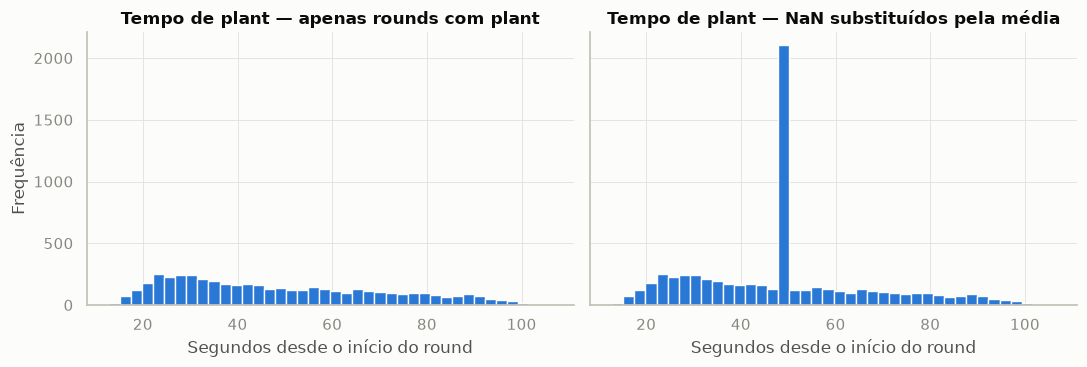

Desvio-padrão antes: 22.1 | depois: 18.5


In [20]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
axs[0].hist(rounds["plant_tempo_s"].dropna(), bins=40, color=CORES[0])
axs[0].set_title("Tempo de plant — apenas rounds com plant")
axs[1].hist(rounds_media["plant_tempo_s"], bins=40, color=CORES[0])
axs[1].set_title("Tempo de plant — NaN substituídos pela média")
for ax in axs:
    ax.set_xlabel("Segundos desde o início do round")
axs[0].set_ylabel("Frequência")
plt.tight_layout()
plt.show()

print("Desvio-padrão antes:", round(rounds["plant_tempo_s"].std(), 1),
      "| depois:", round(rounds_media["plant_tempo_s"].std(), 1))

A imputação cria um pico artificial de ~1.965 rounds com plant exatamente na média e reduz o desvio-padrão. Pior: ela **inventa plants que não aconteceram**. Esse é um ausente **estrutural** — o valor não existe porque o evento não ocorreu — e imputá-lo não faz sentido.

Para valores ausentes estruturais, o tratamento adequado é:
- manter o `NaN` na variável contínua (as análises de tempo de plant consideram só rounds com plant);
- criar uma **variável indicadora** (`houve_plant`, `houve_defuse`) e uma categoria explícita para a variável categórica (`plant_site = "Sem plant"`).

A imputação por média ou mediana é apropriada quando o valor **existe, mas não foi registrado** (falha de sensor, campo não preenchido), e quando a fração ausente é pequena.

In [21]:
rounds_limpo = rounds.copy()
rounds_limpo["houve_plant"] = rounds_limpo["plant_tempo_s"].notna()
rounds_limpo["houve_defuse"] = rounds_limpo["defuse_tempo_s"].notna()
rounds_limpo["plant_site"] = rounds_limpo["plant_site"].fillna("Sem plant")
rounds_limpo["atacante_venceu"] = (rounds_limpo["lado_vencedor"] == "Attacker").astype(int)

print(rounds_limpo["plant_site"].value_counts())
print("\nTaxa de vitória do ataque com e sem plant:")
print(rounds_limpo.groupby("houve_plant")["atacante_venceu"].mean().round(3))

plant_site
A            2040
Sem plant    1965
B            1603
C            1010
Name: count, dtype: int64

Taxa de vitória do ataque com e sem plant:
houve_plant
False    0.067
True     0.708
Name: atacante_venceu, dtype: float64


Sem plant, o ataque vence apenas ~7% dos rounds (só quando elimina os cinco defensores). Essa informação se perderia com a imputação.

### 8. Engenharia de atributos, normalização e padronização

As contagens brutas (kills, dano, score) crescem com a duração da partida: um jogo de 26 rounds gera mais kills do que um 13-0. Para comparar jogadores, usamos métricas **por round**, as mesmas usadas pela comunidade competitiva (vlr.gg, tracker.gg):

| métrica | definição |
|---|---|
| `acs` | *Average Combat Score* = score / rounds |
| `adr` | *Average Damage per Round* = dano em inimigos / rounds |
| `kd` | kills / deaths |
| `kda` | (kills + assists) / deaths |
| `kast_pct` | % de rounds com **K**ill, **A**ssist, **S**obrevivência ou morte **T**rocada (≤ 5 s) |
| `hs_pct` | % dos acertos que foram na cabeça |
| `fk_round`, `fd_round` | first kills e first deaths por round |
| `kpr`, `dpr`, `apr` | kills, deaths e assists por round |
| `casts_round` | habilidades usadas por round |
| `loadout_medio` | valor médio do equipamento por round |

Nenhum jogador terminou uma partida com 0 deaths, então `kd` não tem divisões por zero.

In [22]:
n = data_limpa["n_rounds"]
data_limpa["acs"] = data_limpa["score"] / n
data_limpa["adr"] = data_limpa["dano"] / n
data_limpa["kd"] = data_limpa["kills"] / data_limpa["deaths"]
data_limpa["kda"] = (data_limpa["kills"] + data_limpa["assists"]) / data_limpa["deaths"]
data_limpa["kast_pct"] = 100 * data_limpa["kast_rounds"] / n
data_limpa["hs_pct"] = 100 * data_limpa["headshots"] / data_limpa[["headshots", "bodyshots", "legshots"]].sum(axis=1)
data_limpa["fk_round"] = data_limpa["first_kills"] / n
data_limpa["fd_round"] = data_limpa["first_deaths"] / n
data_limpa["kpr"] = data_limpa["kills"] / n
data_limpa["dpr"] = data_limpa["deaths"] / n
data_limpa["apr"] = data_limpa["assists"] / n
data_limpa["casts_round"] = data_limpa[["grenade_casts", "ability1_casts", "ability2_casts", "ultimate_casts"]].sum(axis=1) / n
data_limpa["loadout_medio"] = data_limpa["loadout_total"] / n

print("Divisões por zero (inf):", np.isinf(data_limpa.select_dtypes("number")).sum().sum())
metricas = ["acs", "adr", "kd", "kast_pct", "hs_pct", "fk_round"]
data_limpa[["jogador", "time", "agente", "mapa"] + metricas].head()

Divisões por zero (inf): 0


,jogador,time,agente,mapa,acs,adr,kd,kast_pct,hs_pct,fk_round
0,Driblas#TTS,Unicamp Tritons Red,Sova,Haven,182.913043,128.478261,0.812500,73.913043,12.962963,0.086957
1,drs1 rei de itu#banco,Unicamp Tritons Red,Waylay,Haven,225.130435,175.956522,1.187500,60.869565,35.849057,0.130435
2,goavyy#2022,Unicamp Tritons Red,Omen,Haven,142.086957,115.478261,0.562500,65.217391,13.725490,0.130435
3,makola#deft,Unicamp Tritons Red,Chamber,Haven,165.869565,125.043478,0.722222,60.869565,20.000000,0.086957
4,Vks#bru,Poli Plague,Chamber,Haven,375.782609,239.043478,2.000000,73.913043,15.384615,0.347826


Muitos algoritmos de aprendizado de máquina são sensíveis à escala dos atributos. Aqui a escala varia enormemente: o ACS fica na casa das centenas, o KD perto de 1 e first kills por round perto de 0,1. Em k-NN ou k-means, o ACS dominaria todas as distâncias.

#### Normalização Min-Max

$
x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
$

#### Padronização

$
z = \frac{x - \mu}{\sigma}
$

In [23]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

X = np.array(data_limpa[metricas], dtype=float)
y = data_limpa["funcao"]

print("Dimensão da matriz de atributos:", X.shape)
print("Classes (função do agente):", np.unique(y))
print()
for i, nome in enumerate(metricas):
    print(f"{nome:9s}: mínimo = {X[:, i].min():8.2f}, máximo = {X[:, i].max():8.2f}")

Dimensão da matriz de atributos: (3360, 6)
Classes (função do agente): ['Controlador' 'Duelista' 'Iniciador' 'Sentinela']

acs      : mínimo =     5.27, máximo =   514.61
adr      : mínimo =     4.43, máximo =   305.67
kd       : mínimo =     0.00, máximo =    16.00
kast_pct : mínimo =    14.29, máximo =   100.00
hs_pct   : mínimo =     0.00, máximo =    90.00
fk_round : mínimo =     0.00, máximo =     0.61


#### 8.1 Normalização Min-Max

In [24]:
scaler_minmax = MinMaxScaler(feature_range=(0, 1))
X_norm = scaler_minmax.fit_transform(X)

print("Dados normalizados (5 primeiras linhas):")
print(X_norm[:5].round(3))
print("\nMínimo dos atributos normalizados:", np.amin(X_norm, axis=0))
print("Máximo dos atributos normalizados:", np.amax(X_norm, axis=0))

Dados normalizados (5 primeiras linhas):
[[0.349 0.412 0.051 0.696 0.144 0.142]
 [0.432 0.569 0.074 0.543 0.398 0.213]
 [0.269 0.369 0.035 0.594 0.153 0.213]
 [0.315 0.4   0.045 0.543 0.222 0.142]
 [0.727 0.779 0.125 0.696 0.171 0.569]]

Mínimo dos atributos normalizados: [0. 0. 0. 0. 0. 0.]
Máximo dos atributos normalizados: [1. 1. 1. 1. 1. 1.]


#### 8.2 Padronização

In [25]:
scaler_standard = StandardScaler()
X_padronizado = scaler_standard.fit_transform(X)

print("Dados padronizados (5 primeiras linhas):")
print(X_padronizado[:5].round(3))
print()
for i, nome in enumerate(metricas):
    print(f"{nome:9s}: média = {np.mean(X_padronizado[:, i]):7.4f}, desvio padrão = {np.std(X_padronizado[:, i]):.4f}")

Dados padronizados (5 primeiras linhas):
[[-0.284 -0.133 -0.387  0.202 -1.31  -0.144]
 [ 0.321  0.939  0.034 -0.693  0.884  0.344]
 [-0.87  -0.426 -0.667 -0.395 -1.237  0.344]
 [-0.529 -0.21  -0.488 -0.693 -0.636 -0.144]
 [ 2.482  2.364  0.946  0.202 -1.078  2.784]]

acs      : média = -0.0000, desvio padrão = 1.0000
adr      : média = -0.0000, desvio padrão = 1.0000
kd       : média = -0.0000, desvio padrão = 1.0000
kast_pct : média = -0.0000, desvio padrão = 1.0000
hs_pct   : média = -0.0000, desvio padrão = 1.0000
fk_round : média = -0.0000, desvio padrão = 1.0000


#### 8.3 Comparação visual

As transformações mudam a **escala**, mas não a **forma** da distribuição. Note também o efeito de *outliers* na normalização Min-Max: no KD, um único valor extremo (KD = 16: 16 kills e 1 death) comprime quase todos os jogadores na faixa [0; 0,2].

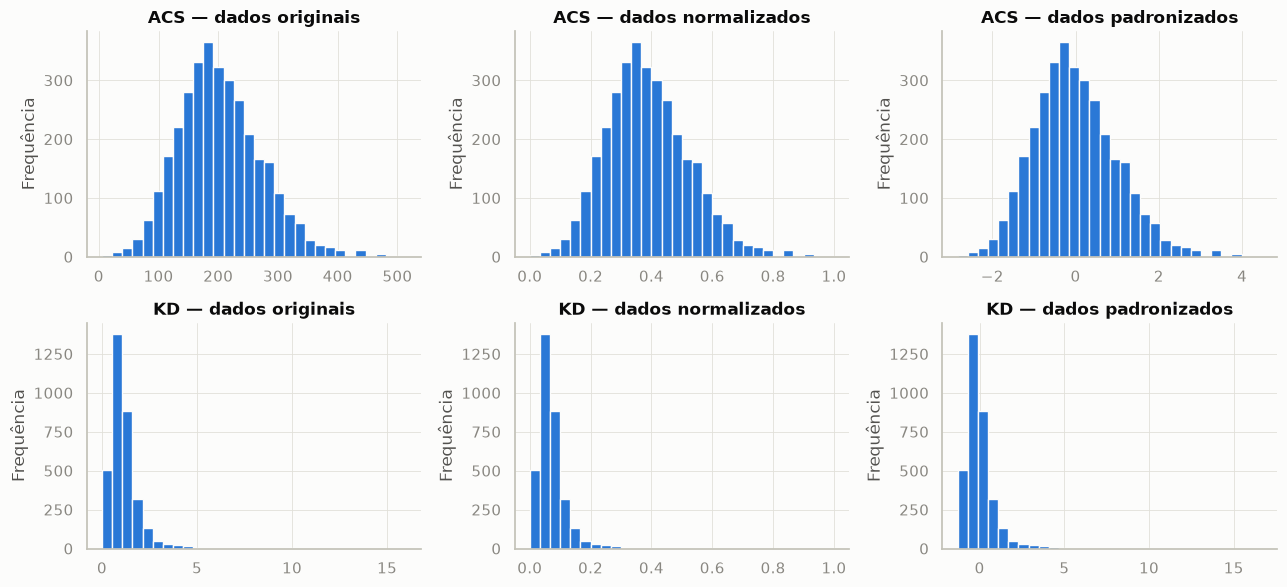

In [26]:
fig, axs = plt.subplots(2, 3, figsize=(13, 6))
for linha, coluna in enumerate([metricas.index("acs"), metricas.index("kd")]):
    nome_coluna = metricas[coluna]
    for ax, valores, titulo in zip(axs[linha],
                                   [X[:, coluna], X_norm[:, coluna], X_padronizado[:, coluna]],
                                   ["originais", "normalizados", "padronizados"]):
        ax.hist(valores, bins=30, color=CORES[0])
        ax.set_title(f"{nome_coluna.upper()} — dados {titulo}")
        ax.set_ylabel("Frequência")
plt.tight_layout()
plt.show()

### 9. Binarização dos dados

A binarização transforma valores numéricos em 0 ou 1 a partir de um limiar $T$. Em Valorant há um limiar com significado natural: **KD = 1** (o jogador matou mais do que morreu).

> Atenção: o `Binarizer` do scikit-learn usa a desigualdade estrita, $X > T \Rightarrow 1$.

In [27]:
from sklearn.preprocessing import Binarizer

T = 1.0
print("Limiar:", T)
binarizer = Binarizer(threshold=T)
kd_positivo = binarizer.fit_transform(data_limpa[["kd"]]).ravel()
data_limpa["kd_positivo"] = kd_positivo.astype(int)

for i in range(5):
    print(f"KD = {data_limpa['kd'].iloc[i]:.2f}  ->  {kd_positivo[i]:.0f}")

print("\nFração de jogadores com KD > 1:")
print(data_limpa.groupby("venceu")["kd_positivo"].mean().rename({False: "time perdeu", True: "time venceu"}).round(3))

Limiar: 1.0
KD = 0.81  ->  0
KD = 1.19  ->  1
KD = 0.56  ->  0
KD = 0.72  ->  0
KD = 2.00  ->  1

Fração de jogadores com KD > 1:
venceu
time perdeu    0.19
time venceu    0.72
Name: kd_positivo, dtype: float64


### 10. Conversão de variáveis categóricas em inteiros

A coluna `funcao` (Controlador, Duelista, Iniciador, Sentinela) é categórica. Podemos substituir cada função por um número inteiro.

> Atenção: essa codificação cria uma ordem artificial (Sentinela = 3 não é "maior" que Controlador = 0). Para variáveis nominais, prefira o **one-hot encoding**. Para o alvo binário `venceu`, a conversão para 0/1 é natural.

In [28]:
print("Coluna original com as classes:")
print(data_limpa["funcao"].head(10).tolist())

classes = np.unique(data_limpa["funcao"])
mapeamento = {classe: numero for numero, classe in enumerate(classes)}
print("\nMapeamento usado:", mapeamento)

data_codificada = data_limpa.copy()
data_codificada["funcao"] = data_codificada["funcao"].map(mapeamento)
data_codificada["venceu"] = data_codificada["venceu"].astype(int)

print("\nColunas codificadas:")
print(data_codificada[["funcao", "venceu"]].head(10))

Coluna original com as classes:
['Iniciador', 'Duelista', 'Controlador', 'Sentinela', 'Sentinela', 'Duelista', 'Duelista', 'Controlador', 'Iniciador', 'Duelista']

Mapeamento usado: {'Controlador': 0, 'Duelista': 1, 'Iniciador': 2, 'Sentinela': 3}

Colunas codificadas:
   funcao  venceu
0       2       1
1       1       1
2       0       1
3       3       1
4       3       0
5       1       1
6       1       0
7       0       0
8       2       0
9       1       0


### 11. One-hot encoding

O **one-hot encoding** cria uma coluna binária por categoria. Aplicamos a `funcao` e `mapa`. Com `drop_first=True`, uma categoria de cada variável é removida (vira a referência) para evitar redundância perfeita entre colunas.

In [29]:
df_onehot = pd.get_dummies(data_limpa[["funcao", "mapa"]], drop_first=True, dtype=int)
print("Colunas criadas:", list(df_onehot.columns))
df_onehot.head()

Colunas criadas: ['funcao_Duelista', 'funcao_Iniciador', 'funcao_Sentinela', 'mapa_Ascent', 'mapa_Breeze', 'mapa_Fracture', 'mapa_Haven', 'mapa_Lotus', 'mapa_Pearl', 'mapa_Split', 'mapa_Summit', 'mapa_Sunset']


,funcao_Duelista,funcao_Iniciador,funcao_Sentinela,mapa_Ascent,mapa_Breeze,mapa_Fracture,mapa_Haven,mapa_Lotus,mapa_Pearl,mapa_Split,mapa_Summit,mapa_Sunset
0,0,1,0,0,0,0,1,0,0,0,0,0
1,1,0,0,0,0,0,1,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,0,0
3,0,0,1,0,0,0,1,0,0,0,0,0
4,0,0,1,0,0,0,1,0,0,0,0,0


### 12. Identificação de variáveis correlacionadas

Quando duas variáveis são muito correlacionadas, elas carregam informação semelhante. Calculamos a matriz de correlação entre as contagens brutas e as métricas por round.

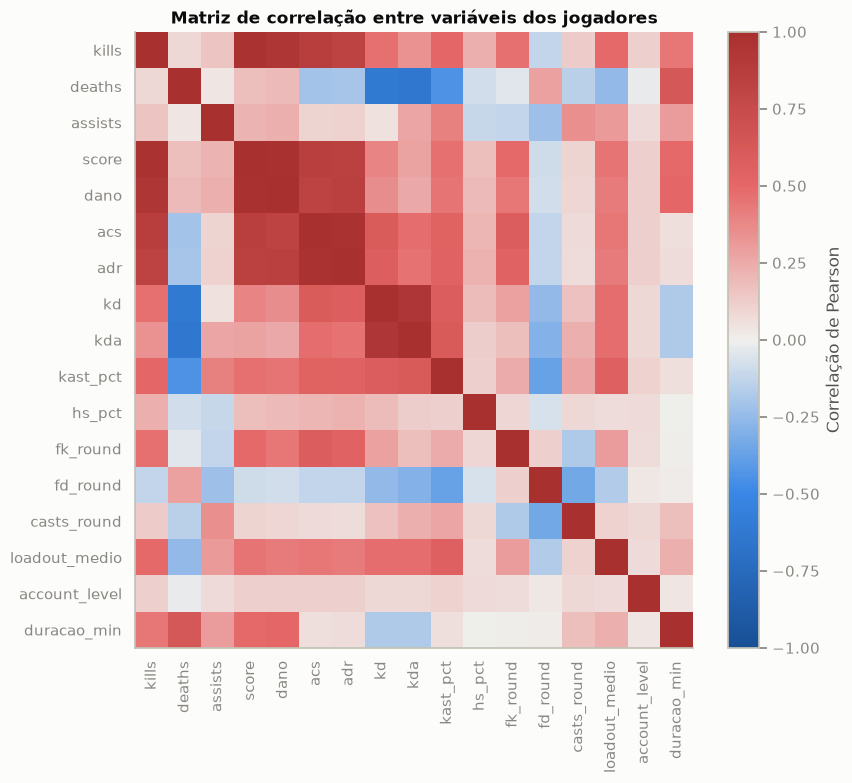

In [30]:
variaveis_corr = ["kills", "deaths", "assists", "score", "dano", "acs", "adr", "kd", "kda", "kast_pct",
                  "hs_pct", "fk_round", "fd_round", "casts_round", "loadout_medio", "account_level", "duracao_min"]
corr = data_limpa[variaveis_corr].corr(numeric_only=True)

plt.figure(figsize=(9, 8))
plt.imshow(corr, cmap=CMAP_DIV, vmin=-1, vmax=1, interpolation="none", aspect="auto")
plt.colorbar(label="Correlação de Pearson")
plt.xticks(range(len(corr)), corr.columns, rotation="vertical")
plt.yticks(range(len(corr)), corr.columns)
plt.title("Matriz de correlação entre variáveis dos jogadores")
plt.grid(False)
plt.show()

In [31]:
corr.round(2)

,kills,deaths,assists,score,dano,acs,adr,kd,kda,kast_pct,hs_pct,fk_round,fd_round,casts_round,loadout_medio,account_level,duracao_min
kills,1.00,0.08,0.15,0.97,0.94,0.86,0.83,0.46,0.34,0.51,0.23,0.47,-0.12,0.13,0.49,0.11,0.44
deaths,0.08,1.00,0.04,0.18,0.19,-0.20,-0.20,-0.61,-0.63,-0.44,-0.08,-0.05,0.28,-0.15,-0.25,-0.02,0.63
assists,0.15,0.04,1.00,0.21,0.23,0.09,0.11,0.05,0.27,0.41,-0.11,-0.12,-0.23,0.35,0.31,0.08,0.30
score,0.97,0.18,0.21,1.00,0.98,0.86,0.84,0.38,0.28,0.46,0.18,0.49,-0.09,0.09,0.45,0.11,0.48
dano,0.94,0.19,0.23,0.98,1.00,0.83,0.85,0.36,0.26,0.45,0.19,0.44,-0.09,0.09,0.43,0.11,0.50
acs,0.86,-0.20,0.09,0.86,0.83,1.00,0.97,0.59,0.47,0.55,0.21,0.58,-0.12,0.07,0.44,0.11,0.06
adr,0.83,-0.20,0.11,0.84,0.85,0.97,1.00,0.58,0.46,0.54,0.22,0.54,-0.12,0.07,0.42,0.12,0.06
kd,0.46,-0.61,0.05,0.38,0.36,0.59,0.58,1.00,0.94,0.58,0.18,0.28,-0.26,0.16,0.48,0.08,-0.17
kda,0.34,-0.63,0.27,0.28,0.26,0.47,0.46,0.94,1.00,0.60,0.12,0.17,-0.29,0.23,0.47,0.08,-0.18
kast_pct,0.51,-0.44,0.41,0.46,0.45,0.55,0.54,0.58,0.60,1.00,0.12,0.25,-0.37,0.27,0.56,0.10,0.06


Agora identificamos os pares cuja correlação absoluta é maior que um limiar $p$.

In [32]:
p = 0.75
pares_correlacionados = []

# Percorre apenas metade da matriz para evitar repetir pares.
for i, col_i in enumerate(corr.columns):
    for j, col_j in enumerate(corr.columns):
        if j > i and abs(corr.loc[col_i, col_j]) > p:
            pares_correlacionados.append((col_i, col_j, corr.loc[col_i, col_j]))

print(f"Pares com correlação absoluta maior que {p}:")
for col_i, col_j, valor in sorted(pares_correlacionados, key=lambda t: -abs(t[2])):
    print(f"{col_i:>8s} -- {col_j:<8s}: correlação = {valor:.3f}")

Pares com correlação absoluta maior que 0.75:
   score -- dano    : correlação = 0.979
   kills -- score   : correlação = 0.974
     acs -- adr     : correlação = 0.973
   kills -- dano    : correlação = 0.941
      kd -- kda     : correlação = 0.937
   kills -- acs     : correlação = 0.860
   score -- acs     : correlação = 0.859
    dano -- adr     : correlação = 0.851
   score -- adr     : correlação = 0.839
   kills -- adr     : correlação = 0.828
    dano -- acs     : correlação = 0.825


Interpretação:

- `score`, `kills` e `dano` estão quase perfeitamente correlacionados (r ≈ 0,94–0,98): o score do Valorant é calculado principalmente a partir de dano e abates. Além disso, os três crescem com a duração da partida.
- `acs` e `adr` (r ≈ 0,97) praticamente medem a mesma coisa. Em um modelo, manter os dois traz redundância.
- `kd` e `kda` também são fortemente ligados por construção.

> Em uma aplicação real, a decisão de remover uma variável não deve depender apenas da correlação. Aqui, a decisão é guiada pelo significado: **descartamos as contagens brutas** (dependem da duração) e mantemos métricas por round. Entre ACS e ADR, o ADR é mais "puro" (só dano); o ACS inclui bônus por multi-kills e plants.

### 13. Dados desbalanceados

Na tabela `rounds`, a variável `resultado` (como o round terminou) é muito desbalanceada.

In [33]:
classes = rounds_limpo["resultado"]

print("Número de elementos por classe:")
print(classes.value_counts())
print("\nProporção:")
print(classes.value_counts(normalize=True).round(3))

Número de elementos por classe:
resultado
Eliminated             4597
Bomb defused           1349
Bomb detonated          522
Round timer expired     150
Name: count, dtype: int64

Proporção:
resultado
Eliminated             0.695
Bomb defused           0.204
Bomb detonated         0.079
Round timer expired    0.023
Name: proportion, dtype: float64


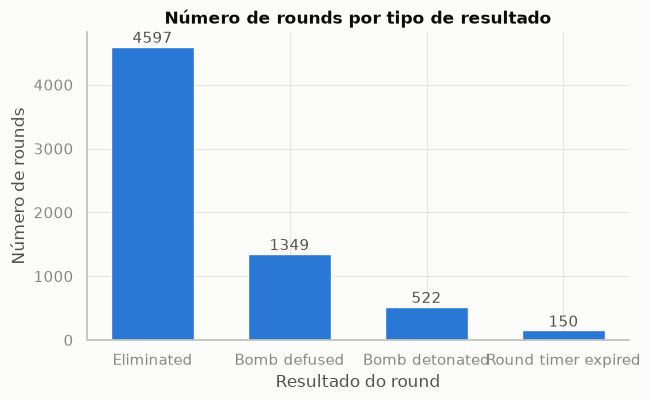

In [34]:
contagem_classes = classes.value_counts()

plt.figure(figsize=(7, 4))
plt.bar(contagem_classes.index, contagem_classes.values, color=CORES[0], width=0.6)
for x, v in enumerate(contagem_classes.values):
    plt.text(x, v + 60, str(v), ha="center", color="#52514e")
plt.title("Número de rounds por tipo de resultado")
plt.xlabel("Resultado do round")
plt.ylabel("Número de rounds")
plt.show()

Um classificador que sempre previsse "Eliminated" teria ~69% de acurácia sem aprender nada — por isso acurácia não é uma boa métrica aqui. Já outros alvos são balanceados: `venceu` é exatamente 50/50 por construção (cada partida tem um vencedor e um perdedor) e o lado vencedor do round fica perto de 52% ataque / 48% defesa.

In [35]:
print("venceu (jogadores):")
print(data_limpa["venceu"].value_counts(normalize=True).round(3))
print("\nlado vencedor (rounds):")
print(rounds_limpo["lado_vencedor"].value_counts(normalize=True).round(3))

venceu (jogadores):
venceu
True     0.5
False    0.5
Name: proportion, dtype: float64

lado vencedor (rounds):
lado_vencedor
Attacker    0.518
Defender    0.482
Name: proportion, dtype: float64


### Subamostragem simples

Selecionamos $N$ observações de cada classe, sem reposição (subamostragem das classes majoritárias).

> Esta técnica pode descartar dados importantes: com $N = 150$ (tamanho da classe minoritária) jogaríamos fora 97% dos rounds "Eliminated". Alternativas: sobreamostragem, SMOTE, pesos por classe ou métricas como F1 e AUC.

In [36]:
N = 5

X = np.array(rounds_limpo[["round", "resultado", "lado_vencedor", "plant_site", "loadout_atk", "loadout_def"]])
cls = np.array(rounds_limpo["resultado"])
classes_unicas = np.unique(cls)

amostras = []
for classe in classes_unicas:
    indices_classe = np.argwhere(cls == classe).ravel()
    indices_sorteados = np.random.choice(indices_classe, N, replace=False)
    amostras.append(X[indices_sorteados, :])

X_balanceado = np.vstack(amostras)

print("Dados obtidos a partir da amostragem:")
pd.DataFrame(X_balanceado, columns=["round", "resultado", "lado_vencedor", "plant_site", "loadout_atk", "loadout_def"])

Dados obtidos a partir da amostragem:


,round,resultado,lado_vencedor,plant_site,loadout_atk,loadout_def
0,18,Bomb defused,Defender,A,23800,19650
1,16,Bomb defused,Defender,C,21150,19150
2,6,Bomb defused,Defender,A,15250,23950
3,7,Bomb defused,Defender,A,23400,10850
4,4,Bomb defused,Defender,C,24150,22550
5,21,Bomb detonated,Attacker,A,23650,22450
6,16,Bomb detonated,Attacker,A,21950,22750
7,10,Bomb detonated,Attacker,C,22650,7800
8,8,Bomb detonated,Attacker,A,24550,20500
9,16,Bomb detonated,Attacker,B,20200,11900


### Exercícios de fixação (adaptados aos dados de Valorant)

1. Leia novamente a tabela `economia`, faça a limpeza dos dados e remova as duas últimas colunas.
2. Leia novamente a tabela `rounds` e substitua os tempos de plant ausentes pela **mediana**. Compare com a média.
3. Mostre o histograma de cada métrica de desempenho antes e depois da normalização.
4. Mostre o histograma de cada métrica de desempenho antes e depois da padronização.
5. Reamostre a tabela `rounds` selecionando 10 elementos de cada tipo de resultado.

In [37]:
# 1. Leia novamente a tabela `economia`, faça a limpeza dos dados e remova as duas últimas colunas.

data_01 = tabelas["economia"].copy()

# Realizar a limpeza consiste em
#   a. Tratar valores ausentes escondidos ("" -> NaN)
#   b. Remover valores ausentes com dropna()
#   c. Remover linhas duplicadas com drop_duplicates()
data_01_tratado = data_01.replace("", np.nan)
data_01_limpo = data_01_tratado.dropna().drop_duplicates()

# Remover as duas últimas colunas (arma_uuid e armadura_uuid)
print("Colunas removidas:", list(data_01_limpo.columns[[-2, -1]]))
data_01_removido = data_01_limpo.drop(data_01_limpo.columns[[-2, -1]], axis=1)

print(f"Restam {data_01_removido.shape[0]} linhas e {data_01_removido.shape[1]} colunas")
print(f"Atenção: o dropna() completo removeu {len(data_01) - len(data_01_limpo)} linhas "
      f"({1 - len(data_01_limpo) / len(data_01):.1%}) — por isso, na seção 5, preferimos 'Sem armadura'.")

Colunas removidas: ['arma_uuid', 'armadura_uuid']
Restam 55619 linhas e 10 colunas
Atenção: o dropna() completo removeu 10561 linhas (16.0%) — por isso, na seção 5, preferimos 'Sem armadura'.


In [38]:
# 2. Substitua os tempos de plant ausentes pela mediana e compare com a média.

data_02 = rounds.copy()  # já com os zeros convertidos em NaN
atributos = ["plant_tempo_s", "defuse_tempo_s"]

print("Média:  ", data_02[atributos].mean().round(2).to_dict())
print("Mediana:", data_02[atributos].median().round(2).to_dict())

data_02_mediana = data_02.copy()
data_02_mediana[atributos] = data_02_mediana[atributos].fillna(data_02_mediana[atributos].median())

print("\nMediana após a imputação (não muda):", data_02_mediana[atributos].median().round(2).to_dict())
print("Média após a imputação (muda):       ", data_02_mediana[atributos].mean().round(2).to_dict())
# A mediana é mais robusta à assimetria, mas o problema conceitual da seção 7 continua:
# rounds sem plant passam a ter um plant fictício.

Média:   {'plant_tempo_s': 48.68, 'defuse_tempo_s': 82.09}
Mediana: {'plant_tempo_s': 44.35, 'defuse_tempo_s': 78.97}

Mediana após a imputação (não muda): {'plant_tempo_s': 44.35, 'defuse_tempo_s': 78.97}
Média após a imputação (muda):        {'plant_tempo_s': 47.39, 'defuse_tempo_s': 79.6}


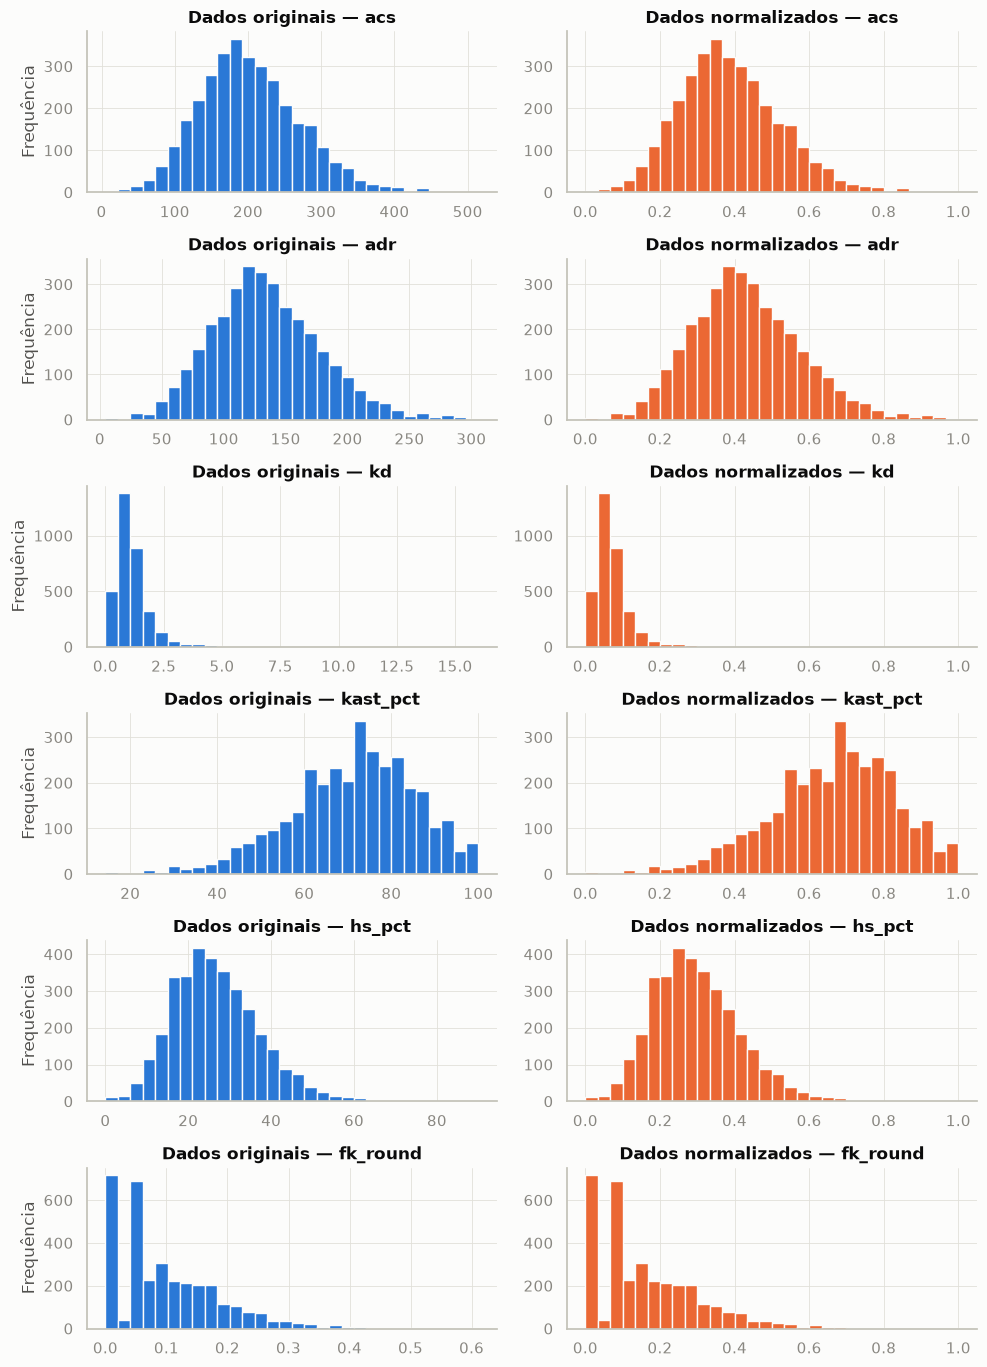

In [39]:
# 3. Histograma de cada métrica antes e depois da normalização.

X = np.array(data_limpa[metricas], dtype=float)
X_norm = MinMaxScaler(feature_range=(0, 1)).fit_transform(X)

fig, axs = plt.subplots(len(metricas), 2, figsize=(10, 2.3 * len(metricas)))
for i, nome_coluna in enumerate(metricas):
    axs[i, 0].hist(X[:, i], bins=30, color=CORES[0])
    axs[i, 0].set_title(f"Dados originais — {nome_coluna}")
    axs[i, 1].hist(X_norm[:, i], bins=30, color=CORES[1])
    axs[i, 1].set_title(f"Dados normalizados — {nome_coluna}")
    axs[i, 0].set_ylabel("Frequência")
plt.tight_layout()
plt.show()

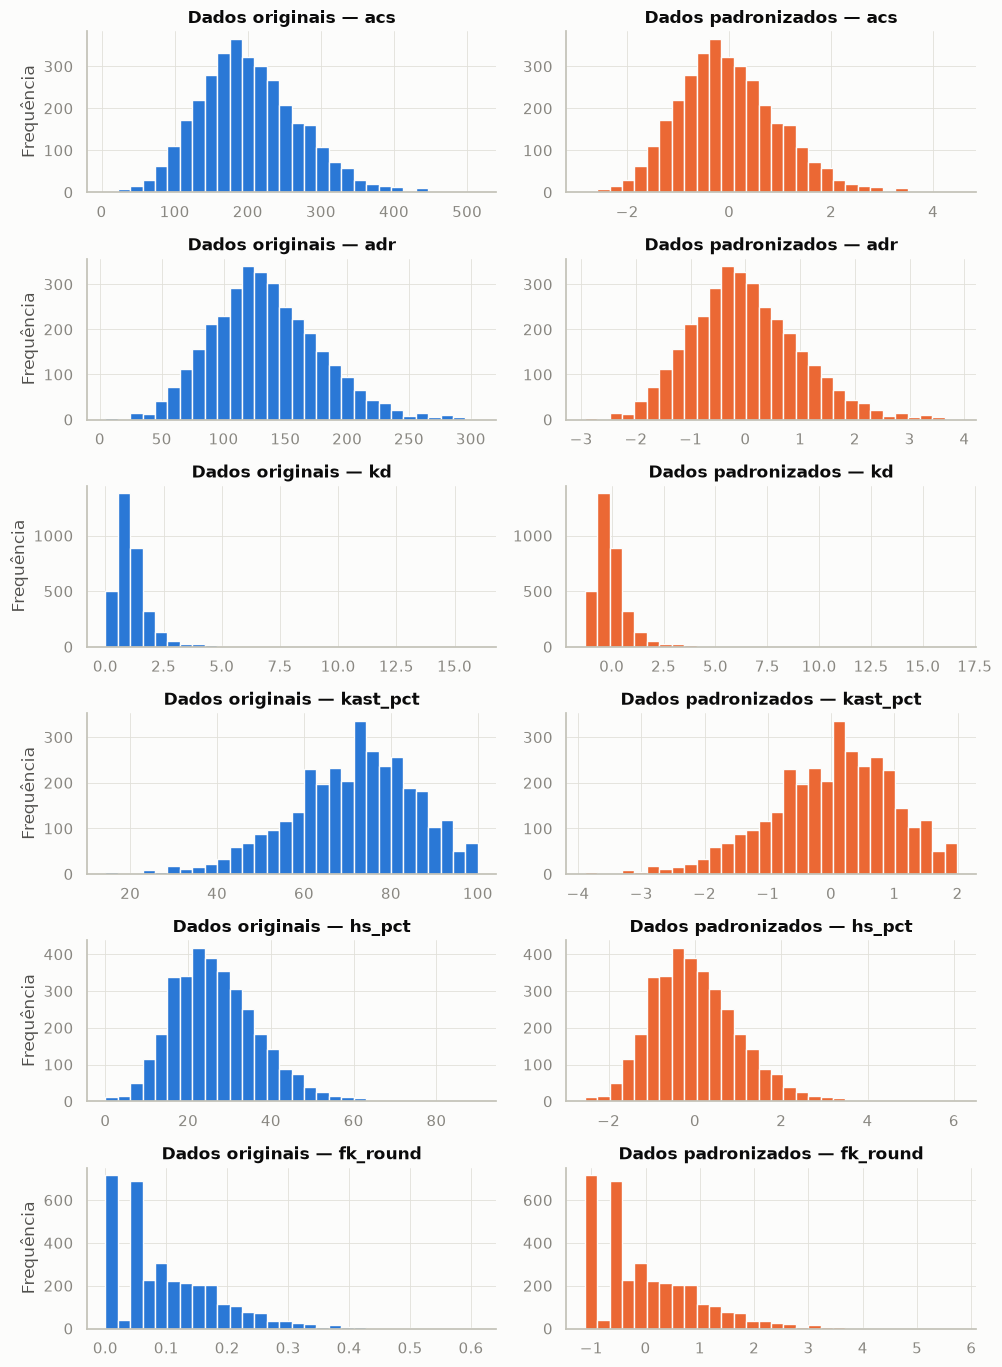

In [40]:
# 4. Histograma de cada métrica antes e depois da padronização.

X_padronizado = StandardScaler().fit_transform(X)

fig, axs = plt.subplots(len(metricas), 2, figsize=(10, 2.3 * len(metricas)))
for i, nome_coluna in enumerate(metricas):
    axs[i, 0].hist(X[:, i], bins=30, color=CORES[0])
    axs[i, 0].set_title(f"Dados originais — {nome_coluna}")
    axs[i, 1].hist(X_padronizado[:, i], bins=30, color=CORES[1])
    axs[i, 1].set_title(f"Dados padronizados — {nome_coluna}")
    axs[i, 0].set_ylabel("Frequência")
plt.tight_layout()
plt.show()

In [41]:
# 5. Reamostre a tabela `rounds` selecionando 10 elementos de cada tipo de resultado.

N = 10
cls = np.array(rounds_limpo["resultado"])
classes_unicas = np.unique(cls)

indices = []
for classe in classes_unicas:
    indices_classe = np.argwhere(cls == classe).ravel()
    indices.extend(np.random.choice(indices_classe, N, replace=False))

data_05_balanceada = rounds_limpo.iloc[indices]

print("Dimensão da amostra balanceada:", data_05_balanceada.shape)
print("Elementos por classe:")
print(data_05_balanceada["resultado"].value_counts())
data_05_balanceada[["torneio", "mapa", "round", "resultado", "lado_vencedor", "plant_site"]].head(12)

Dimensão da amostra balanceada: (40, 31)
Elementos por classe:
resultado
Bomb defused           10
Bomb detonated         10
Eliminated             10
Round timer expired    10
Name: count, dtype: int64


,torneio,mapa,round,resultado,lado_vencedor,plant_site
1578,Univavá,Lotus,24,Bomb defused,Defender,C
6546,Rush Series Inclusivo,Split,3,Bomb defused,Defender,B
3555,Univavá,Ascent,18,Bomb defused,Defender,B
4459,Univavá,Ascent,16,Bomb defused,Defender,B
4129,Univavá,Haven,4,Bomb defused,Defender,C
1980,Univavá,Haven,6,Bomb defused,Defender,C
5409,Rush Series Esquenta,Haven,20,Bomb defused,Defender,A
149,Univavá,Haven,8,Bomb defused,Defender,B
1747,Univavá,Lotus,12,Bomb defused,Defender,C
4823,Univavá,Sunset,1,Bomb defused,Defender,B


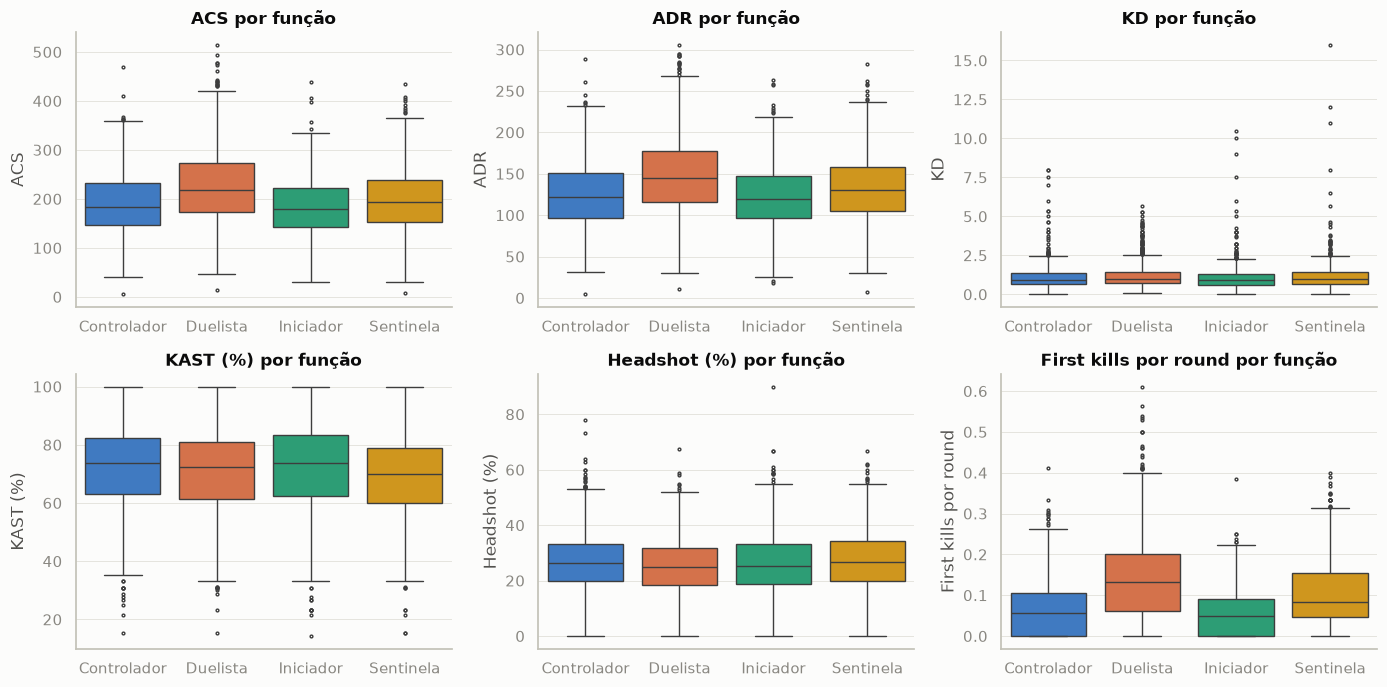

Número de outliers (regra 1,5·IQR) por métrica e função:
             acs  adr  kd  kast_pct  hs_pct  fk_round
funcao                                               
Controlador    7    7  33        12      18        11
Duelista      16   18  68         9       7        20
Iniciador      5   10  39        12      12         6
Sentinela     10    9  31         8       9        17


In [42]:
# Extra: boxplot de cada métrica por função do agente. Quais apresentam outliers?

rotulos = {"acs": "ACS", "adr": "ADR", "kd": "KD", "kast_pct": "KAST (%)", "hs_pct": "Headshot (%)", "fk_round": "First kills por round"}

fig, axs = plt.subplots(2, 3, figsize=(14, 7))
for ax, (coluna, rotulo) in zip(axs.flat, rotulos.items()):
    sns.boxplot(data=data_limpa, x="funcao", y=coluna, hue="funcao", order=ORDEM_FUNCAO,
                palette=CORES_FUNCAO, legend=False, ax=ax, linewidth=1, fliersize=2)
    ax.set_xlabel("")
    ax.set_ylabel(rotulo)
    ax.set_title(f"{rotulo} por função")
plt.tight_layout()
plt.show()

def n_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum())

print("Número de outliers (regra 1,5·IQR) por métrica e função:")
print(data_limpa.groupby("funcao")[list(rotulos)].agg(n_outliers))

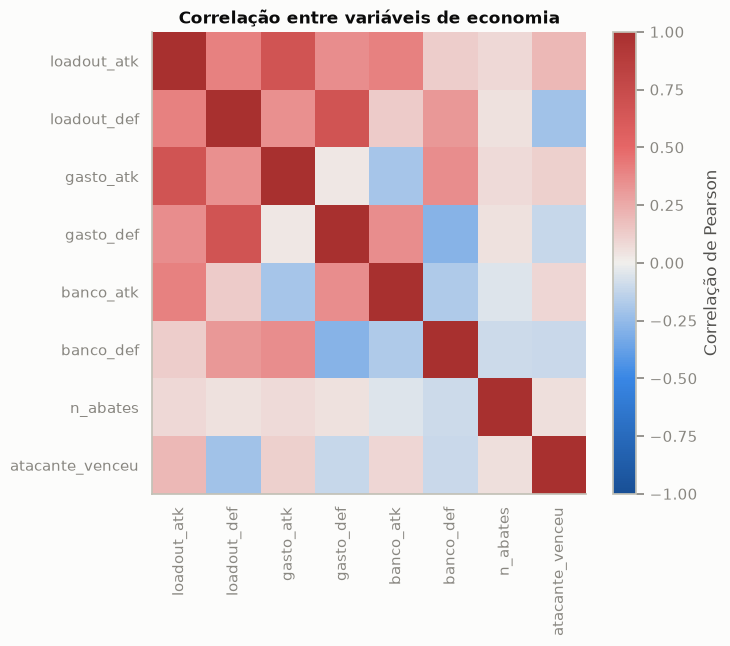

Variáveis mais correlacionadas: loadout_atk e gasto_atk (correlação = 0.671)
Correlação de cada variável com a vitória do ataque:
loadout_def   -0.213
gasto_def     -0.114
banco_def     -0.106
n_abates       0.062
banco_atk      0.091
gasto_atk      0.110
loadout_atk    0.197
Name: atacante_venceu, dtype: float64


In [43]:
# Extra: correlação entre as variáveis de economia dos rounds. Quais são as mais correlacionadas?

data_07 = rounds_limpo[["loadout_atk", "loadout_def", "gasto_atk", "gasto_def", "banco_atk", "banco_def",
                        "n_abates", "atacante_venceu"]]
corr = data_07.corr(numeric_only=True)

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap=CMAP_DIV, vmin=-1, vmax=1, interpolation="none", aspect="auto")
plt.colorbar(label="Correlação de Pearson")
plt.xticks(range(len(corr)), corr.columns, rotation="vertical")
plt.yticks(range(len(corr)), corr.columns)
plt.title("Correlação entre variáveis de economia")
plt.grid(False)
plt.show()

par_mais_correlacionado = None
maior_correlacao = -1
for i, col_i in enumerate(corr.columns):
    for j, col_j in enumerate(corr.columns):
        if j > i and abs(corr.loc[col_i, col_j]) > maior_correlacao:
            maior_correlacao = abs(corr.loc[col_i, col_j])
            par_mais_correlacionado = (col_i, col_j, corr.loc[col_i, col_j])

col_i, col_j, valor = par_mais_correlacionado
print(f"Variáveis mais correlacionadas: {col_i} e {col_j} (correlação = {valor:.3f})")
print("Correlação de cada variável com a vitória do ataque:")
print(corr["atacante_venceu"].drop("atacante_venceu").sort_values().round(3))

### 14. Salvando as bases tratadas

Por fim, tratamos a tabela `abates` (tradução das armas e categoria explícita para o meio do abate) e salvamos as quatro bases em `outputs/processed/`.

In [44]:
abates = tabelas["abates"].copy()
nome_arma = nomear_itens(abates["item_dano"], ref, "weapons")
abates["meio"] = np.where(abates["tipo_dano"] == "Weapon", nome_arma, abates["tipo_dano"])
abates["meio"] = abates["meio"].fillna("Arma desconhecida")
abates["jogador_killer"] = abates["killer"].map(nick_atual)

# Função do agente de quem matou, útil para a análise de armas por função.
agente_partida = data_limpa.set_index(["match_id", "puuid"])[["agente", "funcao"]]
abates = abates.join(agente_partida, on=["match_id", "killer"])

colunas_jogadores = ["torneio", "fase", "codigo", "data", "match_id", "mapa", "versao_jogo", "duracao_min", "n_rounds",
                     "puuid", "jogador", "time", "adversario", "agente", "funcao", "account_level",
                     "rounds_ganhos_time", "rounds_ganhos_adversario", "venceu",
                     "kills", "deaths", "assists", "score", "dano", "dano_recebido", "headshots", "bodyshots", "legshots",
                     "first_kills", "first_deaths", "plants", "defuses", "multikills", "kast_rounds",
                     "acs", "adr", "kd", "kda", "kast_pct", "hs_pct", "fk_round", "fd_round",
                     "kpr", "dpr", "apr", "casts_round", "loadout_medio", "kd_positivo"]

saida = PASTA_PROCESSADOS
saida.mkdir(parents=True, exist_ok=True)
bases = {
    "jogadores": data_limpa[colunas_jogadores],
    "rounds": rounds_limpo,
    "economia": economia_limpa.drop(columns=["arma_uuid", "armadura_uuid"]),
    "abates": abates.drop(columns=["killer", "vitima", "item_dano"]),
}
for nome, base in bases.items():
    base.to_csv(saida / f"{nome}.csv", index=False)
    print(f"outputs/processed/{nome}.csv: {base.shape[0]:>6} linhas x {base.shape[1]} colunas")

outputs/processed/jogadores.csv:   3360 linhas x 48 colunas
outputs/processed/rounds.csv:   6618 linhas x 31 colunas


outputs/processed/economia.csv:  66164 linhas x 12 colunas
outputs/processed/abates.csv:  46753 linhas x 14 colunas


### Resumo das adequações e decisões de limpeza

| problema encontrado | tratamento |
|---|---|
| nomes dos times ausentes no JSON | recuperados do nome do arquivo via placar |
| agentes, armas, armaduras e mapas como UUID/nome interno | tradução com `reference/valorant_reference.json` |
| 22 observadores sem estatísticas (NaN) | removidos com `dropna()` |
| duplicatas aparentes (revanches com mesmo placar) | mantidas: `match_id` distintos |
| mesmo jogador com até 3 nicks | identificação por `puuid` + nick mais recente |
| `""` no lugar de ausente (armadura, arma, plant site) | `replace("", np.nan)` |
| armadura ausente = não comprou | categoria "Sem armadura" (não remover: 16% da base, viés) |
| tempo de plant/defuse = 0 quando não houve | NaN + indicadoras `houve_plant`/`houve_defuse` (não imputar) |
| colunas constantes (região, modo, tier…) | removidas |
| contagens dependentes da duração | métricas por round (ACS, ADR, KAST…) |
| métricas redundantes (score~dano~kills, ACS~ADR) | identificadas pela matriz de correlação |
| `resultado` do round desbalanceado (69% Eliminated) | atenção a métricas; subamostragem ilustrada |